# Experiment 7: Data Processing and Analysis Using Apache Pig

**Aim:** To perform data processing and analysis on a dataset using Apache Pig and Pig Latin scripts.

**Mapped CO(s):** CO2

**Dataset:** Titanic Dataset (`Titanic-Dataset.csv`, 891 passengers)

## 1. Import Required Libraries

In [16]:
import os
import re
import shutil
import subprocess
import time
from io import StringIO
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

## 2. Apache Pig (Brief Theory)

Apache Pig is a high-level platform on top of Hadoop. Scripts are written in **Pig Latin**, and Pig turns them into MapReduce jobs.

**How a Pig script runs**

1. **Parser**: checks the syntax and builds a logical plan.
2. **Optimizer**: rearranges the plan, for example by pushing filters earlier.
3. **Compiler**: converts the plan into a chain of MapReduce jobs.
4. **Execution engine**: submits the jobs to Hadoop. This lab uses `-x mapreduce` mode, so data is read from and written to HDFS.

| Operator | Purpose | Example |
|---|---|---|
| `LOAD` | Read data from HDFS | `t = LOAD 'file' USING PigStorage(',')` |
| `DUMP` | Print a relation to the screen | `DUMP t;` |
| `FILTER` | Keep rows that match a condition | `FILTER t BY Sex == 'female'` |
| `FOREACH ... GENERATE` | Process each row / pick columns | `FOREACH t GENERATE Name, Fare` |
| `GROUP` | Group rows by a field | `GROUP t BY Pclass` |
| `COUNT`, `SUM`, `AVG` | Aggregate a bag | `COUNT(t)` |
| `ORDER` | Sort | `ORDER t BY Fare DESC` |
| `LIMIT` | Take the first N rows | `LIMIT t 5` |
| `STORE` | Save a relation into HDFS | `STORE t INTO 'dir'` |

Passenger names contain commas (`"Braund, Mr. Owen Harris"`), so the CSV is loaded with **`CSVExcelStorage`** from Piggybank. Plain `PigStorage(',')` would split names into two columns.

## 3. Set Java, Hadoop and Pig Environment

In [17]:
EXP_DIR = Path("/Users/ojas/Desktop/DS Lab/Experiment7")
SRC_DIR = EXP_DIR / "src"
DATASET = Path("/Users/ojas/Desktop/DS Lab/Shared/Titanic-Dataset.csv")

WORK_DIR = Path("/tmp/exp7")
BIN_DIR = WORK_DIR / "bin"
LOCAL_DIR = WORK_DIR / "local"
HDFS_DATA = WORK_DIR / "hdfs-data"
CONF_DIR = WORK_DIR / "hadoop-conf"
LOG_DIR = WORK_DIR / "logs"

JAVA_HOME = Path("/opt/homebrew/opt/openjdk@17/libexec/openjdk.jdk/Contents/Home")
HADOOP_HOME = Path("/Users/ojas/hadoop-3.4.1")
PIG_HOME = Path("/Users/ojas/pig-0.18.0")
PIGGYBANK = PIG_HOME / "lib" / "piggybank-0.18.0.jar"

os.environ["JAVA_HOME"] = str(JAVA_HOME)
os.environ["HADOOP_HOME"] = str(HADOOP_HOME)
os.environ["HADOOP_CONF_DIR"] = str(CONF_DIR)
os.environ["HADOOP_LOG_DIR"] = str(LOG_DIR)
os.environ["PIG_HOME"] = str(PIG_HOME)
os.environ["PATH"] = (
    f"{BIN_DIR}:{JAVA_HOME / 'bin'}:{HADOOP_HOME / 'bin'}:{HADOOP_HOME / 'sbin'}:"
    + os.environ["PATH"]
)

for folder in (BIN_DIR, LOCAL_DIR, LOG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# `pig` launcher: Pig jars + the Hadoop classpath (which includes HADOOP_CONF_DIR)
pig_launcher = BIN_DIR / "pig"
pig_launcher.write_text(
    "#!/bin/bash\n"
    'exec java -Xmx1g -cp "$PIG_HOME/lib/*:$(hadoop classpath)" org.apache.pig.Main '
    f'-logfile {LOG_DIR}/pig.log "$@"\n'
)
pig_launcher.chmod(0o755)


NOISE = ("NativeCodeLoader", "log4j", "WARN ", " INFO ")


def clean(text):
    return "\n".join(
        line for line in (text or "").splitlines()
        if not any(word in line for word in NOISE)
    ).strip()


def capture(cmd, check=True):
    result = subprocess.run(
        cmd, shell=True, text=True, capture_output=True, env=os.environ.copy(), cwd=WORK_DIR
    )
    if check and result.returncode != 0:
        print(result.stdout)
        print(result.stderr[-4000:])
        raise RuntimeError(f"Command failed with exit code {result.returncode}: {cmd}")
    return result


def run(cmd, check=True):
    print(f"$ {cmd}")
    result = capture(cmd, check)
    for text in (clean(result.stdout), clean(result.stderr)):
        if text:
            print(text)


run("java -version")
print()
run("hadoop version | head -1")
print()
run("pig -version")

$ java -version
openjdk version "17.0.19" 2026-04-21
OpenJDK Runtime Environment Homebrew (build 17.0.19+0)
OpenJDK 64-Bit Server VM Homebrew (build 17.0.19+0, mixed mode, sharing)

$ hadoop version | head -1
Hadoop 3.4.1

$ pig -version
Apache Pig version 0.18.0 (r1928472) 
compiled Sep 15 2025, 02:27:08


## 4. Start Hadoop (HDFS)

Single-node setup: `fs.defaultFS = hdfs://localhost:8020`, replication = 1. MapReduce jobs created by Pig run with the local job runner and read/write HDFS.

In [18]:
if CONF_DIR.exists():
    shutil.rmtree(CONF_DIR)
shutil.copytree(HADOOP_HOME / "etc" / "hadoop", CONF_DIR)

(CONF_DIR / "core-site.xml").write_text("""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>fs.defaultFS</name>
    <value>hdfs://localhost:8020</value>
  </property>
</configuration>
""")

(CONF_DIR / "hdfs-site.xml").write_text(f"""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property><name>dfs.replication</name><value>1</value></property>
  <property><name>dfs.namenode.name.dir</name><value>file://{HDFS_DATA / 'namenode'}</value></property>
  <property><name>dfs.datanode.data.dir</name><value>file://{HDFS_DATA / 'datanode'}</value></property>
  <property><name>dfs.namenode.http-address</name><value>localhost:9870</value></property>
  <property><name>dfs.datanode.address</name><value>localhost:9866</value></property>
  <property><name>dfs.datanode.http.address</name><value>localhost:9864</value></property>
  <property><name>dfs.datanode.ipc.address</name><value>localhost:9867</value></property>
  <property><name>dfs.permissions.enabled</name><value>false</value></property>
</configuration>
""")

(CONF_DIR / "mapred-site.xml").write_text("""<?xml version="1.0" encoding="UTF-8"?>
<configuration>
  <property>
    <name>mapreduce.framework.name</name>
    <value>local</value>
  </property>
</configuration>
""")

capture("hdfs --daemon stop datanode", check=False)
capture("hdfs --daemon stop namenode", check=False)
time.sleep(2)
if HDFS_DATA.exists():
    shutil.rmtree(HDFS_DATA)
HDFS_DATA.mkdir(parents=True)

capture("hdfs namenode -format -force -nonInteractive")
print("NameNode formatted.")
run("hdfs --daemon start namenode")
run("hdfs --daemon start datanode")

for _ in range(30):
    time.sleep(1)
    report = capture("hdfs dfsadmin -report", check=False)
    if "Live datanodes (1)" in report.stdout:
        break

run("jps")

NameNode formatted.
$ hdfs --daemon start namenode
$ hdfs --daemon start datanode
$ jps
28740 Jps
28678 DataNode
28617 NameNode


## 5. Store the Titanic Dataset in HDFS

In [19]:
shutil.copy2(DATASET, LOCAL_DIR / DATASET.name)

run("hdfs dfs -mkdir -p /user/lab7/titanic")
run(f"hdfs dfs -put -f {LOCAL_DIR / DATASET.name} /user/lab7/titanic/")
run("hdfs dfs -ls /user/lab7/titanic")
print()
run("hdfs dfs -cat /user/lab7/titanic/Titanic-Dataset.csv | head -4")

HDFS_INPUT = "/user/lab7/titanic/Titanic-Dataset.csv"

$ hdfs dfs -mkdir -p /user/lab7/titanic
$ hdfs dfs -put -f /tmp/exp7/local/Titanic-Dataset.csv /user/lab7/titanic/
$ hdfs dfs -ls /user/lab7/titanic
Found 1 items
-rw-r--r--   1 ojas supergroup      60302 2026-10-23 12:11 /user/lab7/titanic/Titanic-Dataset.csv

$ hdfs dfs -cat /user/lab7/titanic/Titanic-Dataset.csv | head -4
PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38,1,0,PC 17599,71.2833,C85,C


## 6. Pig Latin Script

`titanic_analysis.pig` follows the methodology: **load, display, filter, group, count, sort, store**.

In [20]:
print((SRC_DIR / "titanic_analysis.pig").read_text())

-- Experiment 7: Data processing and analysis of the Titanic dataset using Apache Pig
-- Run: pig -x mapreduce -param INPUT=<hdfs csv> -param OUTPUT=<hdfs dir> -param PIGGYBANK=<jar> titanic_analysis.pig

REGISTER '$PIGGYBANK';

-- 1. LOAD the dataset from HDFS (CSVExcelStorage handles quoted names like "Braund, Mr. Owen Harris")
titanic = LOAD '$INPUT'
    USING org.apache.pig.piggybank.storage.CSVExcelStorage(',', 'NO_MULTILINE', 'UNIX', 'SKIP_INPUT_HEADER')
    AS (PassengerId:int, Survived:int, Pclass:int, Name:chararray, Sex:chararray,
        Age:double, SibSp:int, Parch:int, Ticket:chararray, Fare:double,
        Cabin:chararray, Embarked:chararray);

-- 2. DISPLAY the first 5 records
first_five = LIMIT titanic 5;
DUMP first_five;

-- 3. FILTER: passengers who survived
survivors = FILTER titanic BY Survived == 1;
survivor_total = FOREACH (GROUP survivors ALL) GENERATE 'survivors' AS label, COUNT(survivors) AS total;
DUMP survivor_total;

-- 4. GROUP by passenger class
by_class =

## 7. Run the Pig Script in MapReduce Mode

`run_pig` runs `pig -x mapreduce` with parameters. It prints the `DUMP` results (lines that start with `(`) and Pig's job summary (records read and stored).

In [21]:
SUMMARY = ("Successfully read", "Successfully stored", "Success!", "ERROR", "Failed")


def run_pig(script, **params):
    args = " ".join(f'-param {k}="{v}"' for k, v in params.items())
    cmd = f'pig -x mapreduce {args} "{script}"'
    print(f"$ pig -x mapreduce {args} {Path(script).name}\n")
    result = capture(cmd)
    dumps = [line for line in result.stdout.splitlines() if line.startswith("(")]
    if dumps:
        print("DUMP output:")
        print("\n".join(dumps))
        print()
    shown = set()
    for line in result.stderr.splitlines():
        msg = re.sub(r" \(\d+ bytes\)", "", line.split(" - ")[-1].strip())
        msg = re.sub(r'"hdfs://localhost:8020/tmp/temp[^"]*"?', '"temporary DUMP location"', msg)
        if "=" not in msg and any(key in msg for key in SUMMARY) and msg not in shown:
            shown.add(msg)
            print(msg)


def hdfs_table(path, columns, sep="\t"):
    result = capture(f"hdfs dfs -cat {path}/part-*")
    return pd.read_csv(StringIO(clean(result.stdout)), sep=sep, header=None, names=columns)


capture("hdfs dfs -rm -r -f /user/lab7/output", check=False)
run_pig(
    SRC_DIR / "titanic_analysis.pig",
    INPUT=HDFS_INPUT,
    OUTPUT="/user/lab7/output/class_stats",
    PIGGYBANK=PIGGYBANK,
)

$ pig -x mapreduce -param INPUT="/user/lab7/titanic/Titanic-Dataset.csv" -param OUTPUT="/user/lab7/output/class_stats" -param PIGGYBANK="/Users/ojas/pig-0.18.0/lib/piggybank-0.18.0.jar" titanic_analysis.pig

DUMP output:
(1,0,3,Braund, Mr. Owen Harris,male,22.0,1,0,A/5 21171,7.25,,S)
(2,1,1,Cumings, Mrs. John Bradley (Florence Briggs Thayer),female,38.0,1,0,PC 17599,71.2833,C85,C)
(3,1,3,Heikkinen, Miss. Laina,female,26.0,0,0,STON/O2. 3101282,7.925,,S)
(4,1,1,Futrelle, Mrs. Jacques Heath (Lily May Peel),female,35.0,1,0,113803,53.1,C123,S)
(5,0,3,Allen, Mr. William Henry,male,35.0,0,0,373450,8.05,,S)
(survivors,342)
(3,491,119,13.68)
(1,216,136,84.15)
(2,184,87,20.66)

Success!
Successfully read 891 records from: "/user/lab7/titanic/Titanic-Dataset.csv"
Successfully stored 1 records in: "temporary DUMP location"
Successfully stored 3 records in: "temporary DUMP location"
Successfully stored 3 records in: "/user/lab7/output/class_stats"


The first five `DUMP` tuples are the raw passenger records. `(survivors,342)` is the filter result. The last three tuples are `(Pclass, passengers, survived, avg_fare)` sorted by passenger count.

## 8. Read the Stored Output from HDFS

$ hdfs dfs -ls /user/lab7/output/class_stats
Found 2 items
-rw-r--r--   1 ojas supergroup          0 2026-10-23 12:12 /user/lab7/output/class_stats/_SUCCESS
-rw-r--r--   1 ojas supergroup         47 2026-10-23 12:12 /user/lab7/output/class_stats/part-r-00000

$ hdfs dfs -cat /user/lab7/output/class_stats/part-*
3,491,119,13.68
1,216,136,84.15
2,184,87,20.66


,Pclass,passengers,survived,avg_fare,survival_rate_%
0,3,491,119,13.68,24.24
1,1,216,136,84.15,62.96
2,2,184,87,20.66,47.28


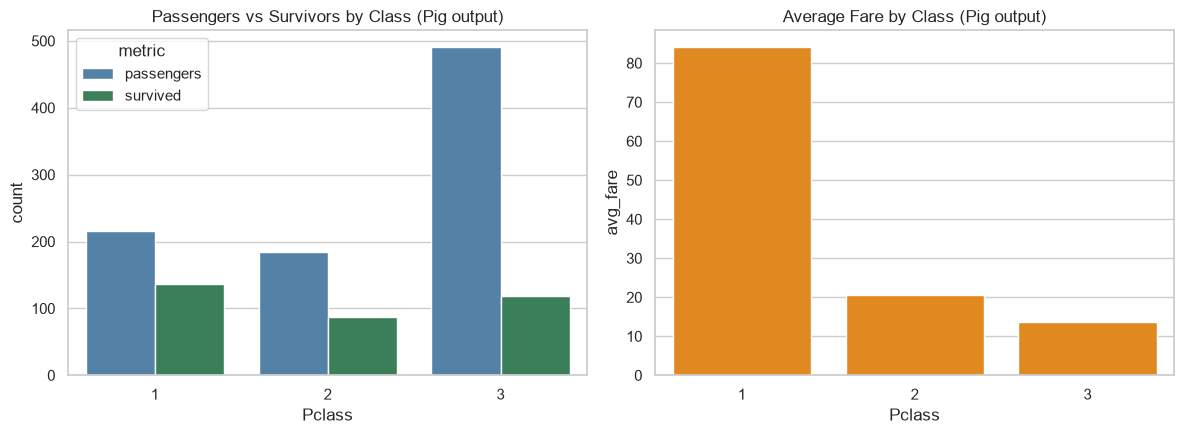

In [22]:
run("hdfs dfs -ls /user/lab7/output/class_stats")
print()
run("hdfs dfs -cat /user/lab7/output/class_stats/part-*")

class_stats = hdfs_table(
    "/user/lab7/output/class_stats", ["Pclass", "passengers", "survived", "avg_fare"], sep=","
)
class_stats["survival_rate_%"] = (class_stats["survived"] / class_stats["passengers"] * 100).round(2)
display(class_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_df = class_stats.sort_values("Pclass").melt(
    id_vars="Pclass", value_vars=["passengers", "survived"], var_name="metric", value_name="count"
)
sns.barplot(data=plot_df, x="Pclass", y="count", hue="metric", ax=axes[0], palette=["steelblue", "seagreen"])
axes[0].set_title("Passengers vs Survivors by Class (Pig output)")
sns.barplot(data=class_stats.sort_values("Pclass"), x="Pclass", y="avg_fare", ax=axes[1], color="darkorange")
axes[1].set_title("Average Fare by Class (Pig output)")
plt.tight_layout()
plt.show()

### Cross-check with pandas

In [23]:
df = pd.read_csv(DATASET)
check = df.groupby("Pclass").agg(
    passengers=("PassengerId", "count"),
    survived=("Survived", "sum"),
    avg_fare=("Fare", "mean"),
).round(2).reset_index()
display(check)

merged = class_stats.sort_values("Pclass").reset_index(drop=True)
print("Pig and pandas results match:", merged[["passengers", "survived", "avg_fare"]].equals(check[["passengers", "survived", "avg_fare"]]))

,Pclass,passengers,survived,avg_fare
0,1,216,136,84.15
1,2,184,87,20.66
2,3,491,119,13.68


Pig and pandas results match: True


---
## Exercises / Assignments

All five exercises are in one script, `exercises.pig`. Each result is stored in its own HDFS directory under `/user/lab7/exercises/`.

In [24]:
print((SRC_DIR / "exercises.pig").read_text())

-- Experiment 7 exercises (Titanic dataset, Apache Pig)
-- Run: pig -x mapreduce -param INPUT=<hdfs csv> -param OUT_DIR=<hdfs dir> -param PIGGYBANK=<jar> exercises.pig

REGISTER '$PIGGYBANK';

titanic = LOAD '$INPUT'
    USING org.apache.pig.piggybank.storage.CSVExcelStorage(',', 'NO_MULTILINE', 'UNIX', 'SKIP_INPUT_HEADER')
    AS (PassengerId:int, Survived:int, Pclass:int, Name:chararray, Sex:chararray,
        Age:double, SibSp:int, Parch:int, Ticket:chararray, Fare:double,
        Cabin:chararray, Embarked:chararray);

-- Exercise 1: only female passengers
females = FILTER titanic BY Sex == 'female';
female_view = FOREACH females GENERATE PassengerId, Name, Pclass, Age, Fare, Survived;
STORE female_view INTO '$OUT_DIR/ex1_female_passengers' USING PigStorage('\t');

-- Exercise 2: number of passengers in each class
by_class = GROUP titanic BY Pclass;
class_count = FOREACH by_class GENERATE group AS Pclass, COUNT(titanic) AS passengers;
class_count_sorted = ORDER class_count BY Pclass

In [25]:
EX_DIR = "/user/lab7/exercises"
capture(f"hdfs dfs -rm -r -f {EX_DIR}", check=False)
run_pig(SRC_DIR / "exercises.pig", INPUT=HDFS_INPUT, OUT_DIR=EX_DIR, PIGGYBANK=PIGGYBANK)

$ pig -x mapreduce -param INPUT="/user/lab7/titanic/Titanic-Dataset.csv" -param OUT_DIR="/user/lab7/exercises" -param PIGGYBANK="/Users/ojas/pig-0.18.0/lib/piggybank-0.18.0.jar" exercises.pig

Success!
Successfully read 891 records from: "/user/lab7/titanic/Titanic-Dataset.csv"
Successfully stored 5 records in: "/user/lab7/exercises/ex5_filter_demo"
Successfully stored 5 records in: "/user/lab7/exercises/ex5_foreach_demo"
Successfully stored 314 records in: "/user/lab7/exercises/ex1_female_passengers"
Successfully stored 3 records in: "/user/lab7/exercises/ex2_class_count"
Successfully stored 891 records in: "/user/lab7/exercises/ex3_sorted_by_fare"
Successfully stored 3 records in: "/user/lab7/exercises/ex4_female_summary"


### Exercise 1: Filter only female passengers

```pig
females = FILTER titanic BY Sex == 'female';
```

In [26]:
females = hdfs_table(
    f"{EX_DIR}/ex1_female_passengers", ["PassengerId", "Name", "Pclass", "Age", "Fare", "Survived"]
)
print("Female passengers:", len(females))
display(females.head(10))

Female passengers: 314


,PassengerId,Name,Pclass,Age,Fare,Survived
0,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,71.2833,1
1,3,"Heikkinen, Miss. Laina",3,26.0,7.9250,1
2,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,53.1000,1
3,9,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",3,27.0,11.1333,1
4,10,"Nasser, Mrs. Nicholas (Adele Achem)",2,14.0,30.0708,1
5,11,"Sandstrom, Miss. Marguerite Rut",3,4.0,16.7000,1
6,12,"Bonnell, Miss. Elizabeth",1,58.0,26.5500,1
7,15,"Vestrom, Miss. Hulda Amanda Adolfina",3,14.0,7.8542,0
8,16,"Hewlett, Mrs. (Mary D Kingcome)",2,55.0,16.0000,1
9,19,"Vander Planke, Mrs. Julius (Emelia Maria Vande...",3,31.0,18.0000,0


314 of the 891 passengers are female. `FILTER` kept only rows where `Sex == 'female'`, and all other columns are unchanged.

### Exercise 2: Count the number of passengers in each class

```pig
by_class = GROUP titanic BY Pclass;
class_count = FOREACH by_class GENERATE group AS Pclass, COUNT(titanic) AS passengers;
```

,Pclass,passengers
0,1,216
1,2,184
2,3,491


Total: 891


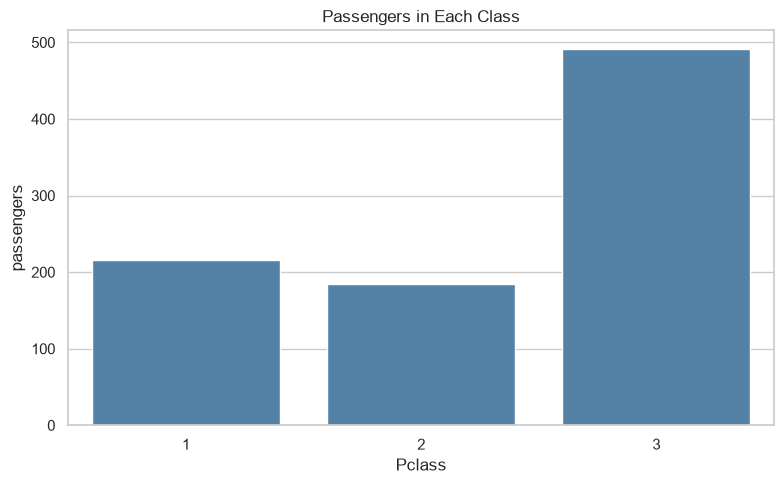

In [27]:
class_count = hdfs_table(f"{EX_DIR}/ex2_class_count", ["Pclass", "passengers"])
display(class_count)
print("Total:", class_count["passengers"].sum())

sns.barplot(data=class_count, x="Pclass", y="passengers", color="steelblue")
plt.title("Passengers in Each Class")
plt.tight_layout()
plt.show()

3rd class has the most passengers (491), followed by 1st class (216) and 2nd class (184). The total is 891, which matches the dataset.

### Exercise 3: Sort passengers by Fare in descending order

```pig
by_fare = ORDER fare_view BY Fare DESC, PassengerId ASC;
```

In [28]:
by_fare = hdfs_table(f"{EX_DIR}/ex3_sorted_by_fare", ["PassengerId", "Name", "Pclass", "Fare"])
print("Top 10 fares:")
display(by_fare.head(10))
print("Lowest 5 fares:")
display(by_fare.tail(5))

Top 10 fares:


,PassengerId,Name,Pclass,Fare
0,259,"Ward, Miss. Anna",1,512.3292
1,680,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292
2,738,"Lesurer, Mr. Gustave J",1,512.3292
3,28,"Fortune, Mr. Charles Alexander",1,263.0000
4,89,"Fortune, Miss. Mabel Helen",1,263.0000
5,342,"Fortune, Miss. Alice Elizabeth",1,263.0000
6,439,"Fortune, Mr. Mark",1,263.0000
7,312,"Ryerson, Miss. Emily Borie",1,262.3750
8,743,"Ryerson, Miss. Susan Parker ""Suzette""",1,262.3750
9,119,"Baxter, Mr. Quigg Edmond",1,247.5208


Lowest 5 fares:


,PassengerId,Name,Pclass,Fare
886,675,"Watson, Mr. Ennis Hastings",2,0.0
887,733,"Knight, Mr. Robert J",2,0.0
888,807,"Andrews, Mr. Thomas Jr",1,0.0
889,816,"Fry, Mr. Richard",1,0.0
890,823,"Reuchlin, Jonkheer. John George",1,0.0


The highest fare is **512.33**, paid by three 1st-class passengers. The top of the list is all 1st class. At the bottom are passengers with fare 0 (crew or complimentary tickets).

### Exercise 4: Store the processed output in a new HDFS directory

The female passengers from Exercise 1 are grouped by class, and the summary is stored in the new directory `/user/lab7/exercises/ex4_female_summary`:

```pig
STORE female_summary_sorted INTO '$OUT_DIR/ex4_female_summary' USING PigStorage(',');
```

$ hdfs dfs -ls /user/lab7/exercises
Found 6 items
drwxr-xr-x   - ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex1_female_passengers
drwxr-xr-x   - ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex2_class_count
drwxr-xr-x   - ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex3_sorted_by_fare
drwxr-xr-x   - ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex4_female_summary
drwxr-xr-x   - ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex5_filter_demo
drwxr-xr-x   - ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex5_foreach_demo

$ hdfs dfs -ls /user/lab7/exercises/ex4_female_summary
Found 2 items
-rw-r--r--   1 ojas supergroup          0 2026-10-23 12:12 /user/lab7/exercises/ex4_female_summary/_SUCCESS
-rw-r--r--   1 ojas supergroup         42 2026-10-23 12:12 /user/lab7/exercises/ex4_female_summary/part-r-00000

$ hdfs dfs -cat /user/lab7/exercises/ex4_female_summary/part-*
1,94,91

,Pclass,female_passengers,female_survivors,survival_pct
0,1,94,91,96.81
1,2,76,70,92.11
2,3,144,72,50.00


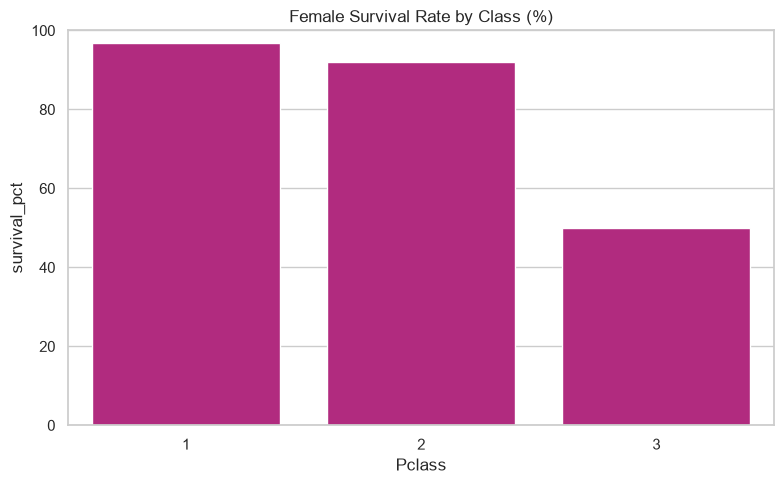

In [29]:
run(f"hdfs dfs -ls {EX_DIR}")
print()
run(f"hdfs dfs -ls {EX_DIR}/ex4_female_summary")
print()
run(f"hdfs dfs -cat {EX_DIR}/ex4_female_summary/part-*")

female_summary = hdfs_table(
    f"{EX_DIR}/ex4_female_summary", ["Pclass", "female_passengers", "female_survivors", "survival_pct"], sep=","
)
display(female_summary)

sns.barplot(data=female_summary, x="Pclass", y="survival_pct", color="mediumvioletred")
plt.title("Female Survival Rate by Class (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

The new directory contains `_SUCCESS` and a `part-*` file, which shows that Pig stored the output in HDFS. Female survival was 96.81% in 1st class and 92.11% in 2nd class, but only 50% in 3rd class.

### Exercise 5: Difference between FILTER and FOREACH in Apache Pig

| | `FILTER` | `FOREACH ... GENERATE` |
|---|---|---|
| Works on | **Rows** (tuples) | **Columns** (fields of each tuple) |
| What it does | Keeps only the rows that satisfy a condition | Processes every row and produces new fields |
| Number of rows | Same or fewer | Same as input (one output per input row) |
| Columns | Unchanged (all columns kept) | Can select, rename, compute, or aggregate columns |
| SQL equivalent | `WHERE` | `SELECT` list |
| Example | `FILTER t BY Age > 70` | `FOREACH t GENERATE Name, UPPER(Sex), Fare * 2` |

The demo below applies `FILTER` first (passengers older than 70), then `FOREACH` on the result.

In [30]:
filter_demo = hdfs_table(
    f"{EX_DIR}/ex5_filter_demo",
    ["PassengerId", "Survived", "Pclass", "Name", "Sex", "Age", "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"],
)
foreach_demo = hdfs_table(f"{EX_DIR}/ex5_foreach_demo", ["Name", "Age", "sex_upper", "double_fare"])

print(f"FILTER output: {filter_demo.shape[0]} rows x {filter_demo.shape[1]} columns (rows removed, columns kept)")
display(filter_demo)
print(f"FOREACH output: {foreach_demo.shape[0]} rows x {foreach_demo.shape[1]} columns (same rows, new columns)")
display(foreach_demo)

FILTER output: 5 rows x 12 columns (rows removed, columns kept)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
1,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
2,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
3,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
4,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.7750,NaN,S


FOREACH output: 5 rows x 4 columns (same rows, new columns)


,Name,Age,sex_upper,double_fare
0,"Goldschmidt, Mr. George B",71.0,MALE,69.3084
1,"Connors, Mr. Patrick",70.5,MALE,15.5000
2,"Artagaveytia, Mr. Ramon",71.0,MALE,99.0084
3,"Barkworth, Mr. Algernon Henry Wilson",80.0,MALE,60.0000
4,"Svensson, Mr. Johan",74.0,MALE,15.5500


`FILTER` reduced 891 rows to 5 but kept all 12 columns. `FOREACH` kept those 5 rows and produced 4 new columns, including computed ones (`UPPER(Sex)` and `Fare * 2`). In short, **FILTER chooses rows** and **FOREACH transforms columns**.

---
## Observation

- The Titanic dataset (891 records) was successfully loaded from HDFS into Apache Pig.
- Passenger records were displayed with `DUMP` and filtered with `FILTER` (342 survivors, 314 females).
- Data was grouped by passenger class with `GROUP`, and `COUNT` gave 216, 184, and 491 passengers for classes 1, 2, and 3.
- Results were sorted with `ORDER` (by passenger count and by fare) and stored in HDFS with `STORE`.
- The Pig results matched an independent pandas calculation.

## Result

Apache Pig successfully processed and analyzed the Titanic dataset. Filtering, grouping, counting, and sorting operations were executed using Pig Latin scripts, demonstrating efficient large-scale data processing.

## Conclusion

The experiment demonstrated the use of Apache Pig for processing and analyzing large datasets. Pig Latin scripts simplified data manipulation tasks such as filtering, grouping, aggregation, and sorting without writing complex MapReduce code. Apache Pig is an efficient tool for big data analysis and ETL operations.